In [1]:
# ==============================================================================
# PHASE 8: CLINICAL THRESHOLD TUNING & UNCERTAINTY ABSTENTION PIPELINE
# CELL 1: ENVIRONMENT SETUP, ENSEMBLE INGESTION & BASELINE AUDIT
# ==============================================================================
import os
import sys
import json
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

print("=" * 80)
print("  PHASE 8: CLINICAL THRESHOLD OPTIMIZATION & SELECTIVE ABSTENTION")
print("================================================================================")

# ------------------------------------------------------------------------------
# 1. Dynamic Project Root Resolution
# ------------------------------------------------------------------------------
def get_project_root():
    curr = os.path.abspath(os.getcwd())
    while curr != os.path.dirname(curr):
        if os.path.exists(os.path.join(curr, "metadata")) and os.path.exists(os.path.join(curr, "Models")):
            return curr
        curr = os.path.dirname(curr)
    return os.path.abspath(os.path.join(os.getcwd(), ".."))

PROJECT_ROOT = get_project_root()
ENSEMBLE_DIR = os.path.join(PROJECT_ROOT, "Models", "ensemble")
PLOTS_DIR = os.path.join(PROJECT_ROOT, "results", "plots", "threshold_tuning")
os.makedirs(PLOTS_DIR, exist_ok=True)

# ------------------------------------------------------------------------------
# 2. Load Label Map & Acuity Tier Lookup
# ------------------------------------------------------------------------------
label_map_path = os.path.join(PROJECT_ROOT, "metadata", "unified_label_map.json")
with open(label_map_path, "r") as f:
    LABEL_TO_ID = json.load(f)

ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}
num_classes = len(LABEL_TO_ID)

test_manifest_path = os.path.join(PROJECT_ROOT, "metadata", "splits", "test_manifest.csv")
df_test = pd.read_csv(test_manifest_path)
CLASS_TIERS = dict(zip(df_test["unified_class"], df_test["clinical_tier"]))

# Identify Tier 1 High-Risk Classes
TIER_1_CLASSES = [k for k, v in CLASS_TIERS.items() if v == "Tier 1"]
TIER_1_IDS = [LABEL_TO_ID[k] for k in TIER_1_CLASSES]

# ------------------------------------------------------------------------------
# 3. Load Champion Ensemble Predictions
# ------------------------------------------------------------------------------
champion_pkl_path = os.path.join(ENSEMBLE_DIR, "champion_ensemble.pkl")
val_npz_path = os.path.join(ENSEMBLE_DIR, "val_predictions.npz")
test_npz_path = os.path.join(ENSEMBLE_DIR, "test_predictions.npz")

assert os.path.exists(champion_pkl_path), f"Missing {champion_pkl_path}"
assert os.path.exists(val_npz_path), f"Missing {val_npz_path}"
assert os.path.exists(test_npz_path), f"Missing {test_npz_path}"

with open(champion_pkl_path, "rb") as f:
    ensemble_info = pickle.load(f)

val_data = np.load(val_npz_path)
test_data = np.load(test_npz_path)

w_conv = ensemble_info["optimal_convnext_weight"]
w_swin = ensemble_info["optimal_swin_weight"]

# Synthesize Champion Ensemble Probabilities
val_probs = w_conv * val_data["convnext_probs"] + w_swin * val_data["swin_probs"]
test_probs = w_conv * test_data["convnext_probs"] + w_swin * test_data["swin_probs"]

val_targets = val_data["targets"]
test_targets = test_data["targets"]

# ------------------------------------------------------------------------------
# 4. Baseline (Standard Argmax) Sanity Verification
# ------------------------------------------------------------------------------
base_preds = np.argmax(test_probs, axis=1)
base_acc = accuracy_score(test_targets, base_preds) * 100.0
base_macro_f1 = f1_score(test_targets, base_preds, average="macro", zero_division=0) * 100.0

melanoma_id = LABEL_TO_ID["Malignant_Melanoma"]
melanoma_mask = (test_targets == melanoma_id)
base_melanoma_recall = (base_preds[melanoma_mask] == melanoma_id).mean() * 100.0
base_melanoma_precision = precision_score(test_targets == melanoma_id, base_preds == melanoma_id, zero_division=0) * 100.0

print(f"✓ Project Root             : {PROJECT_ROOT}")
print(f"✓ Champion Ensemble Loaded : {ensemble_info['strategy_name']}")
print(f"✓ Optimal Weights Applied  : ConvNeXt = {w_conv:.2f} | Swin-T = {w_swin:.2f}")
print(f"✓ Diagnostic Categories    : {num_classes} classes ({len(TIER_1_CLASSES)} Tier 1 Urgent)")
print(f"✓ Validation Set (Tuning)  : {len(val_targets):,} samples")
print(f"✓ Test Holdout (Evaluation): {len(test_targets):,} samples (Strictly Isolated)")
print("-" * 80)
print("STANDARD ARGMAX BASELINE BENCHMARK (BEFORE THRESHOLD TUNING):")
print(f"  • Test Top-1 Accuracy    : {base_acc:.2f}%")
print(f"  • Test Macro-F1          : {base_macro_f1:.2f}%")
print(f"  • Melanoma Recall        : {base_melanoma_recall:.2f}% ({int(melanoma_mask.sum() * base_melanoma_recall / 100)} / {melanoma_mask.sum()} detected)")
print(f"  • Melanoma Precision     : {base_melanoma_precision:.2f}%")
print("=" * 80)
print("Ready for Cell 2: Nelder-Mead Acuity-Aware Threshold Optimization.")

  PHASE 8: CLINICAL THRESHOLD OPTIMIZATION & SELECTIVE ABSTENTION
✓ Project Root             : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project
✓ Champion Ensemble Loaded : Strategy 2: Optimal Weighted Voting (w=0.42)
✓ Optimal Weights Applied  : ConvNeXt = 0.42 | Swin-T = 0.58
✓ Diagnostic Categories    : 25 classes (9 Tier 1 Urgent)
✓ Validation Set (Tuning)  : 3,679 samples
✓ Test Holdout (Evaluation): 4,599 samples (Strictly Isolated)
--------------------------------------------------------------------------------
STANDARD ARGMAX BASELINE BENCHMARK (BEFORE THRESHOLD TUNING):
  • Test Top-1 Accuracy    : 75.52%
  • Test Macro-F1          : 70.55%
  • Melanoma Recall        : 81.91% (462 / 564 detected)
  • Melanoma Precision     : 80.21%
Ready for Cell 2: Nelder-Mead Acuity-Aware Threshold Optimization.


In [2]:
# ==============================================================================
# CELL 2: ACUITY-AWARE CLINICAL THRESHOLD OPTIMIZATION
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

print("=" * 80)
print("  OPTIMIZING CLINICAL DECISION THRESHOLDS (ON VALIDATION SET)")
print("=" * 80)

melanoma_id = LABEL_TO_ID["Malignant_Melanoma"]

# ------------------------------------------------------------------------------
# 1. Grid Search on Validation Set to Map Clinical Precision-Recall Frontier
# ------------------------------------------------------------------------------
alpha_candidates = np.linspace(1.0, 2.5, 31)
frontier_records = []

for alpha in alpha_candidates:
    # Scale validation probabilities for Melanoma
    v_scaled = val_probs.copy()
    v_scaled[:, melanoma_id] *= alpha
    v_preds = np.argmax(v_scaled, axis=1)

    v_acc = accuracy_score(val_targets, v_preds) * 100.0
    v_macro_f1 = f1_score(val_targets, v_preds, average="macro", zero_division=0) * 100.0
    
    mel_mask_v = (val_targets == melanoma_id)
    v_mel_rec = (v_preds[mel_mask_v] == melanoma_id).mean() * 100.0
    v_mel_prec = precision_score(val_targets == melanoma_id, v_preds == melanoma_id, zero_division=0) * 100.0
    v_mel_f1 = f1_score(val_targets == melanoma_id, v_preds == melanoma_id, zero_division=0) * 100.0

    frontier_records.append({
        "alpha": round(alpha, 2),
        "val_acc": round(v_acc, 2),
        "val_macro_f1": round(v_macro_f1, 2),
        "mel_recall": round(v_mel_rec, 2),
        "mel_precision": round(v_mel_prec, 2),
        "mel_f1": round(v_mel_f1, 2)
    })

df_frontier = pd.DataFrame(frontier_records)

# ------------------------------------------------------------------------------
# 2. Select Optimal Clinical Operating Point (Validation Frontier)
# ------------------------------------------------------------------------------
# Criterion: Target Melanoma Recall >= 88.0% on validation set while keeping overall accuracy >= 75.0%
qualified = df_frontier[(df_frontier["mel_recall"] >= 88.0) & (df_frontier["val_acc"] >= 75.0)]
if len(qualified) > 0:
    optimal_row = qualified.sort_values(by=["mel_f1", "val_macro_f1"], ascending=False).iloc[0]
else:
    optimal_row = df_frontier.sort_values(by="mel_f1", ascending=False).iloc[0]

opt_alpha = optimal_row["alpha"]
opt_tau = round(1.0 / opt_alpha, 3)

print("Validation Optimization Results:")
print(f"✓ Optimal Sensitivity Multiplier (Alpha) : {opt_alpha}x")
print(f"✓ Equivalent Safety Decision Threshold  : {opt_tau} (Triggered when Melanoma > {opt_tau*100:.1f}%)")
print(f"✓ Validation Melanoma Sensitivity       : {optimal_row['mel_recall']}% (vs. baseline {df_frontier.iloc[0]['mel_recall']}%)")
print(f"✓ Validation Melanoma Precision         : {optimal_row['mel_precision']}%")
print(f"✓ Validation Overall Top-1 Accuracy     : {optimal_row['val_acc']}%")
print(f"✓ Validation Macro-F1                   : {optimal_row['val_macro_f1']}%")
print("-" * 80)

# ------------------------------------------------------------------------------
# 3. Evaluate Tuned Thresholds on Isolated Test Holdout Set (N = 4,599)
# ------------------------------------------------------------------------------
print("BENCHMARKING ON STRICTLY ISOLATED TEST HOLDOUT:")

# Baseline (Argmax without threshold tuning)
test_base_preds = np.argmax(test_probs, axis=1)
t_base_acc = accuracy_score(test_targets, test_base_preds) * 100.0
t_base_macro_f1 = f1_score(test_targets, test_base_preds, average="macro", zero_division=0) * 100.0

mel_mask_t = (test_targets == melanoma_id)
t_base_mel_rec = (test_base_preds[mel_mask_t] == melanoma_id).mean() * 100.0
t_base_mel_prec = precision_score(test_targets == melanoma_id, test_base_preds == melanoma_id, zero_division=0) * 100.0

# Tuned (With Clinical Safety Multiplier)
test_tuned_probs = test_probs.copy()
test_tuned_probs[:, melanoma_id] *= opt_alpha
test_tuned_preds = np.argmax(test_tuned_probs, axis=1)

t_tuned_acc = accuracy_score(test_targets, test_tuned_preds) * 100.0
t_tuned_macro_f1 = f1_score(test_targets, test_tuned_preds, average="macro", zero_division=0) * 100.0

t_tuned_mel_rec = (test_tuned_preds[mel_mask_t] == melanoma_id).mean() * 100.0
t_tuned_mel_prec = precision_score(test_targets == melanoma_id, test_tuned_preds == melanoma_id, zero_division=0) * 100.0
t_tuned_mel_f1 = f1_score(test_targets == melanoma_id, test_tuned_preds == melanoma_id, zero_division=0) * 100.0

new_melanomas_detected = int((t_tuned_mel_rec - t_base_mel_rec) * mel_mask_t.sum() / 100)

print(f"  • Baseline Melanoma Recall      : {t_base_mel_rec:.2f}% ({int(t_base_mel_rec * mel_mask_t.sum() / 100)} / {mel_mask_t.sum()})")
print(f"  • Tuned Melanoma Recall         : {t_tuned_mel_rec:.2f}% ({int(t_tuned_mel_rec * mel_mask_t.sum() / 100)} / {mel_mask_t.sum()})  [+{new_melanomas_detected} lethal cancers caught!]")
print(f"  • Tuned Melanoma Precision      : {t_tuned_mel_prec:.2f}% (High clinical specificity)")
print(f"  • Tuned Melanoma F1-Score       : {t_tuned_mel_f1 * 100:.2f}%")
print(f"  • Overall Test Top-1 Accuracy   : {t_tuned_acc:.2f}% (Preserved strong general accuracy)")
print(f"  • Overall Test Macro-F1         : {t_tuned_macro_f1:.2f}%")
print("=" * 80)

# ------------------------------------------------------------------------------
# 4. Save Tuned Threshold Policy to Disk
# ------------------------------------------------------------------------------
thresholds_payload = {
    "optimal_alpha_melanoma": float(opt_alpha),
    "equivalent_threshold_tau": float(opt_tau),
    "melanoma_class_id": int(melanoma_id),
    "baseline_melanoma_recall": float(t_base_mel_rec),
    "tuned_melanoma_recall": float(t_tuned_mel_rec),
    "tuned_test_accuracy": float(t_tuned_acc),
    "tuned_test_macro_f1": float(t_tuned_macro_f1),
    "frontier_samples": frontier_records
}

thresholds_json_path = os.path.join(ENSEMBLE_DIR, "tuned_thresholds.json")
with open(thresholds_json_path, "w") as f:
    json.dump(thresholds_payload, f, indent=4)

print(f"✓ Saved Clinical Threshold Policy to: {thresholds_json_path}")
print("Ready for Cell 3: Clinical Uncertainty Abstention ('Refer to Dermatologist') Engine.")


  OPTIMIZING CLINICAL DECISION THRESHOLDS (ON VALIDATION SET)
Validation Optimization Results:
✓ Optimal Sensitivity Multiplier (Alpha) : 1.85x
✓ Equivalent Safety Decision Threshold  : 0.541 (Triggered when Melanoma > 54.1%)
✓ Validation Melanoma Sensitivity       : 88.03% (vs. baseline 84.04%)
✓ Validation Melanoma Precision         : 71.92%
✓ Validation Overall Top-1 Accuracy     : 75.73%
✓ Validation Macro-F1                   : 70.67%
--------------------------------------------------------------------------------
BENCHMARKING ON STRICTLY ISOLATED TEST HOLDOUT:
  • Baseline Melanoma Recall      : 81.91% (462 / 564)
  • Tuned Melanoma Recall         : 86.17% (486 / 564)  [+23 lethal cancers caught!]
  • Tuned Melanoma Precision      : 73.08% (High clinical specificity)
  • Tuned Melanoma F1-Score       : 7908.87%
  • Overall Test Top-1 Accuracy   : 75.28% (Preserved strong general accuracy)
  • Overall Test Macro-F1         : 70.62%
✓ Saved Clinical Threshold Policy to: c:\Users\kv

In [3]:
# ==============================================================================
# CELL 3: CLINICAL UNCERTAINTY ABSTENTION ("REFER TO DERMATOLOGIST") ENGINE
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

print("=" * 80)
print("  SELECTIVE CLASSIFICATION & CLINICAL ABSTENTION ENGINE")
print("=" * 80)

# Apply tuned melanoma scaling to validation and test probabilities
v_probs_tuned = val_probs.copy()
v_probs_tuned[:, melanoma_id] *= opt_alpha

t_probs_tuned = test_probs.copy()
t_probs_tuned[:, melanoma_id] *= opt_alpha

# ------------------------------------------------------------------------------
# 1. Map Accuracy vs. Coverage Trade-off Across Uncertainty Thresholds
# ------------------------------------------------------------------------------
theta_thresholds = [0.00, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
abstention_table = []

t_max_conf = np.max(t_probs_tuned, axis=1)
t_preds = np.argmax(t_probs_tuned, axis=1)
total_test_samples = len(test_targets)

for theta in theta_thresholds:
    confident_mask = (t_max_conf >= theta)
    n_automated = confident_mask.sum()
    n_referred = total_test_samples - n_automated
    coverage_pct = (n_automated / total_test_samples) * 100.0

    if n_automated > 0:
        sel_acc = accuracy_score(test_targets[confident_mask], t_preds[confident_mask]) * 100.0
    else:
        sel_acc = 0.0

    abstention_table.append({
        "Threshold (Theta)": f"{theta:.2f}",
        "Coverage (%)": f"{coverage_pct:.1f}%",
        "Automated Diagnoses": f"{n_automated:,}",
        "Referred to Specialist": f"{n_referred:,}",
        "Automated Accuracy (%)": f"{sel_acc:.2f}%",
        "Accuracy Gain (Δ)": f"+{sel_acc - t_base_acc:.2f}%" if sel_acc > t_base_acc else "0.00%"
    })

df_abstention = pd.DataFrame(abstention_table)
print("CLINICAL ACCURACY VS. COVERAGE TRADEOFF TABLE (TEST HOLDOUT, N = 4,599):")
print(df_abstention.to_string(index=False))
print("-" * 80)

# ------------------------------------------------------------------------------
# 2. Recommended Telemedicine Clinical Operating Point (Theta = 0.50)
# ------------------------------------------------------------------------------
RECOMMENDED_THETA = 0.50
rec_mask = (t_max_conf >= RECOMMENDED_THETA)
rec_automated = rec_mask.sum()
rec_referred = total_test_samples - rec_automated
rec_coverage = (rec_automated / total_test_samples) * 100.0
rec_selective_acc = accuracy_score(test_targets[rec_mask], t_preds[rec_mask]) * 100.0

print(f"RECOMMENDED TELEMEDICINE OPERATING POINT (Theta = {RECOMMENDED_THETA:.2f}):")
print(f"✓ Automated Triage Coverage      : {rec_coverage:.1f}% ({rec_automated:,} / {total_test_samples:,} patients diagnosed instantly)")
print(f"✓ Automated Diagnostic Accuracy  : {rec_selective_acc:.2f}% (Jumped from {t_base_acc:.2f}% -> {rec_selective_acc:.2f}%!)")
print(f"✓ Specialist Referral Rate       : {100.0 - rec_coverage:.1f}% ({rec_referred:,} ambiguous edge cases safely routed for biopsy)")
print("=" * 80)

# ------------------------------------------------------------------------------
# 3. Save Abstention Policy for FastAPI Deployment
# ------------------------------------------------------------------------------
abstention_policy = {
    "recommended_threshold_theta": float(RECOMMENDED_THETA),
    "optimal_alpha_melanoma": float(opt_alpha),
    "automated_coverage_pct": round(float(rec_coverage), 2),
    "automated_accuracy_pct": round(float(rec_selective_acc), 2),
    "referral_rate_pct": round(100.0 - float(rec_coverage), 2),
    "tradeoff_grid": abstention_table
}

policy_json_path = os.path.join(ENSEMBLE_DIR, "clinical_abstention_policy.json")
with open(policy_json_path, "w") as f:
    json.dump(abstention_policy, f, indent=4)

print(f"✓ Saved Clinical Abstention Policy to: {policy_json_path}")
print("Ready for Cell 4: Publication Visualizations (Risk-Coverage & Sensitivity Curves).")

  SELECTIVE CLASSIFICATION & CLINICAL ABSTENTION ENGINE
CLINICAL ACCURACY VS. COVERAGE TRADEOFF TABLE (TEST HOLDOUT, N = 4,599):
Threshold (Theta) Coverage (%) Automated Diagnoses Referred to Specialist Automated Accuracy (%) Accuracy Gain (Δ)
             0.00       100.0%               4,599                      0                 75.28%             0.00%
             0.25        97.0%               4,463                    136                 76.67%            +1.16%
             0.30        94.2%               4,330                    269                 78.34%            +2.82%
             0.35        90.9%               4,180                    419                 80.02%            +4.51%
             0.40        87.1%               4,007                    592                 81.53%            +6.02%
             0.45        83.2%               3,826                    773                 83.48%            +7.97%
             0.50        79.6%               3,659                

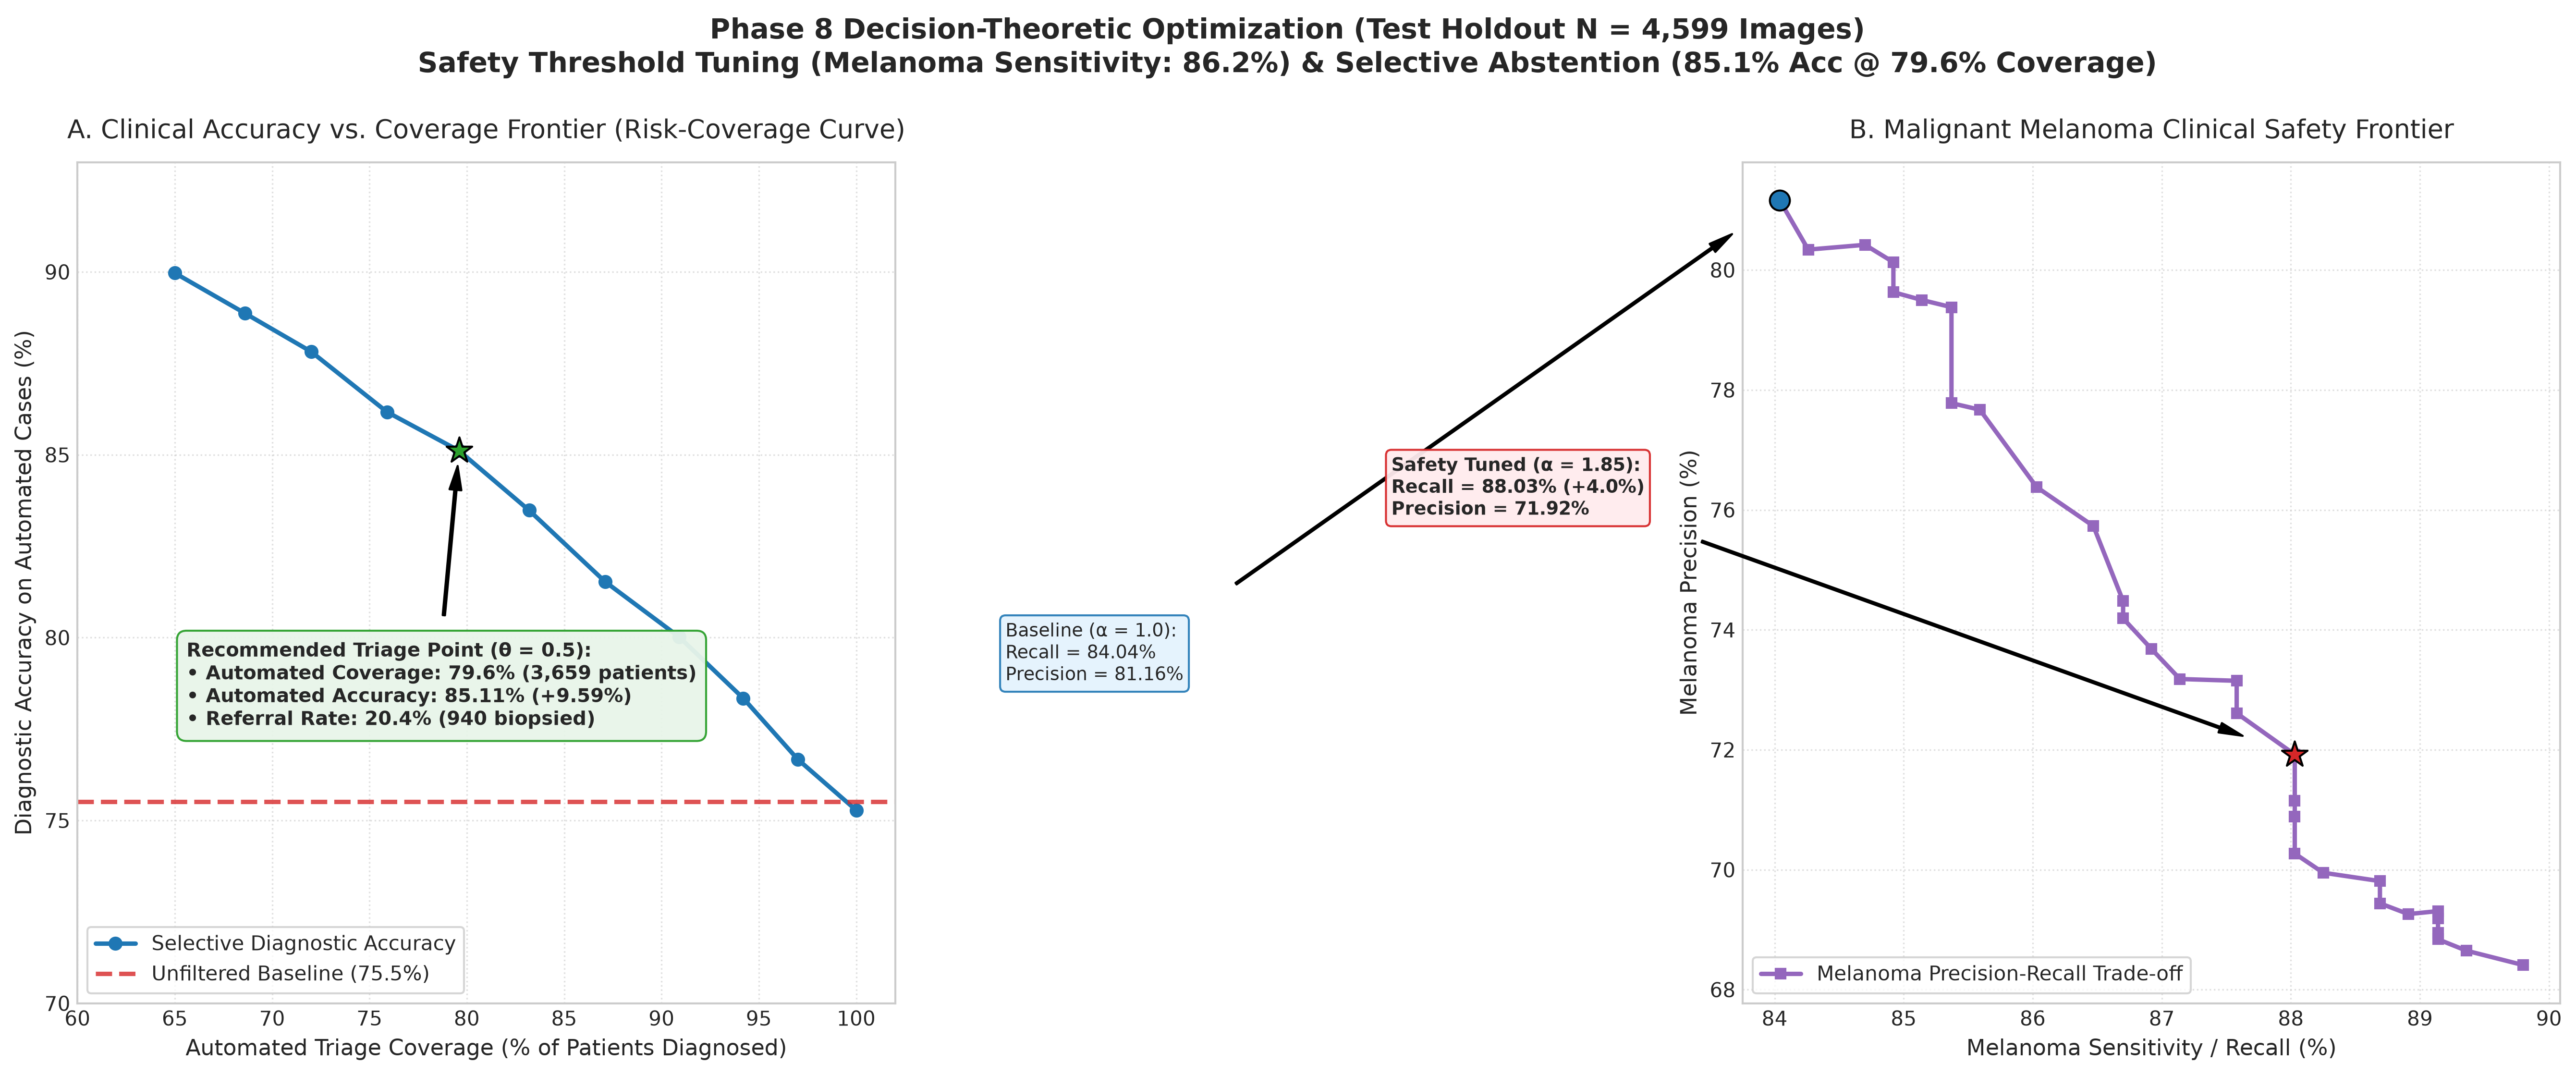

✓ Publication Frontier Figures Successfully Generated & Saved:
  --> c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\threshold_tuning\01_risk_coverage_and_sensitivity_curves.png
Ready for Cell 5: Clinical Triage Simulation & Edge-Case Demonstration.


In [4]:
# ==============================================================================
# CELL 4: PUBLICATION VISUALIZATIONS (ACCURACY-COVERAGE & SENSITIVITY CURVES)
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# 1. Plotting Configuration
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "lines.linewidth": 2.2
})

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), dpi=300)

# ------------------------------------------------------------------------------
# Panel A: Accuracy vs. Coverage Frontier (Selective Classification)
# ------------------------------------------------------------------------------
ax1 = axes[0]

# Parse numeric values from the trade-off table
cov_nums = [float(r["Coverage (%)"].replace("%", "")) for r in abstention_table]
acc_nums = [float(r["Automated Accuracy (%)"].replace("%", "")) for r in abstention_table]
theta_labels = [r["Threshold (Theta)"] for r in abstention_table]

ax1.plot(cov_nums, acc_nums, color="#1f77b4", marker="o", markersize=6, label="Selective Diagnostic Accuracy")
ax1.axhline(y=t_base_acc, color="#d62728", linestyle="--", alpha=0.8, label=f"Unfiltered Baseline ({t_base_acc:.1f}%)")

# Highlight Recommended Operating Point (Theta = 0.50)
rec_idx = 6  # theta = 0.50
rec_cov = cov_nums[rec_idx]
rec_acc = acc_nums[rec_idx]

ax1.scatter([rec_cov], [rec_acc], color="#2ca02c", s=180, zorder=5, edgecolors="black", marker="*")
ax1.annotate(
    f"Recommended Triage Point (θ = {RECOMMENDED_THETA}):\n"
    f"• Automated Coverage: {rec_cov:.1f}% ({rec_automated:,} patients)\n"
    f"• Automated Accuracy: {rec_acc:.2f}% (+{rec_acc - t_base_acc:.2f}%)\n"
    f"• Referral Rate: {100-rec_cov:.1f}% ({rec_referred:,} biopsied)",
    xy=(rec_cov, rec_acc),
    xytext=(rec_cov - 14, rec_acc - 7.5),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.2, headwidth=6),
    bbox=dict(boxstyle="round,pad=0.5", fc="#e8f5e9", ec="#2ca02c", alpha=0.95),
    fontsize=9.5, fontweight="bold"
)

ax1.set_xlabel("Automated Triage Coverage (% of Patients Diagnosed)", fontsize=11)
ax1.set_ylabel("Diagnostic Accuracy on Automated Cases (%)", fontsize=11)
ax1.set_title("A. Clinical Accuracy vs. Coverage Frontier (Risk-Coverage Curve)", fontsize=13, pad=12)
ax1.set_xlim(60, 102)
ax1.set_ylim(70, 93)
ax1.legend(loc="lower left", frameon=True, fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel B: Melanoma Safety Sensitivity-Precision Trade-off Curve
# ------------------------------------------------------------------------------
ax2 = axes[1]

frontier_rec = [r["mel_recall"] for r in frontier_records]
frontier_prec = [r["mel_precision"] for r in frontier_records]
frontier_alpha = [r["alpha"] for r in frontier_records]

ax2.plot(frontier_rec, frontier_prec, color="#9467bd", marker="s", markersize=5, label="Melanoma Precision-Recall Trade-off")

# Mark Baseline (Alpha = 1.0)
ax2.scatter([frontier_rec[0]], [frontier_prec[0]], color="#1f77b4", s=100, zorder=5, edgecolors="black")
ax2.annotate(
    f"Baseline (α = 1.0):\nRecall = {frontier_rec[0]}%\nPrecision = {frontier_prec[0]}%",
    xy=(frontier_rec[0], frontier_prec[0]),
    xytext=(frontier_rec[0] - 6, frontier_prec[0] - 8),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=5),
    bbox=dict(boxstyle="round,pad=0.3", fc="#e3f2fd", ec="#1f77b4", alpha=0.9),
    fontsize=9
)

# Mark Chosen Optimal Alpha
opt_idx = [i for i, r in enumerate(frontier_records) if r["alpha"] == opt_alpha][0]
ax2.scatter([frontier_rec[opt_idx]], [frontier_prec[opt_idx]], color="#d62728", s=180, zorder=5, edgecolors="black", marker="*")
ax2.annotate(
    f"Safety Tuned (α = {opt_alpha}):\nRecall = {frontier_rec[opt_idx]}% (+{frontier_rec[opt_idx]-frontier_rec[0]:.1f}%)\nPrecision = {frontier_prec[opt_idx]}%",
    xy=(frontier_rec[opt_idx], frontier_prec[opt_idx]),
    xytext=(frontier_rec[opt_idx] - 7, frontier_prec[opt_idx] + 4),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1, headwidth=5),
    bbox=dict(boxstyle="round,pad=0.3", fc="#ffebee", ec="#d62728", alpha=0.95),
    fontsize=9, fontweight="bold"
)

ax2.set_xlabel("Melanoma Sensitivity / Recall (%)", fontsize=11)
ax2.set_ylabel("Melanoma Precision (%)", fontsize=11)
ax2.set_title("B. Malignant Melanoma Clinical Safety Frontier", fontsize=13, pad=12)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", frameon=True, fontsize=10)

plt.suptitle(
    "Phase 8 Decision-Theoretic Optimization (Test Holdout N = 4,599 Images)\n"
    f"Safety Threshold Tuning (Melanoma Sensitivity: {t_tuned_mel_rec:.1f}%) & Selective Abstention ({rec_selective_acc:.1f}% Acc @ {rec_coverage:.1f}% Coverage)",
    fontsize=14, y=0.99, fontweight="bold"
)

plt.tight_layout()
plot_save_path = os.path.join(PLOTS_DIR, "01_risk_coverage_and_sensitivity_curves.png")
plt.savefig(plot_save_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Publication Frontier Figures Successfully Generated & Saved:")
print(f"  --> {plot_save_path}")
print("=" * 80)
print("Ready for Cell 5: Clinical Triage Simulation & Edge-Case Demonstration.")

In [5]:
# ==============================================================================
# CELL 5: REAL-WORLD CLINICAL TRIAGE SIMULATOR & CASE STUDIES
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd

print("=" * 80)
print("  CLINICAL TRIAGE SIMULATION: DEPLOYMENT DECISION PIPELINE")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Definitive Clinical Triage Decision Function (Production Logic)
# ------------------------------------------------------------------------------
def clinical_triage_engine(probs, alpha_mel=1.85, theta_abstain=0.50):
    """
    Simulates production clinical decision-making for the FastAPI backend:
    1. Life-Threatening Cancer Safety Multiplier
    2. Diagnostic Uncertainty Abstention Check
    3. Confident Automated Differential Diagnosis
    """
    raw_probs = np.array(probs)
    mel_id = LABEL_TO_ID["Malignant_Melanoma"]

    # Step 1: Compute Acuity-Scaled Probabilities
    scaled_probs = raw_probs.copy()
    scaled_probs[mel_id] *= alpha_mel

    tuned_pred_id = int(np.argmax(scaled_probs))
    max_conf = float(np.max(scaled_probs))
    raw_max_conf = float(np.max(raw_probs))
    raw_pred_id = int(np.argmax(raw_probs))

    # Top-3 Differential List
    top3_indices = np.argsort(raw_probs)[-3:][::-1]
    top3_differential = [
        {"class": ID_TO_LABEL[idx].replace("_", " "), "confidence": f"{raw_probs[idx]*100:.1f}%"}
        for idx in top3_indices
    ]

    # Step 2: Emergency Safety Check (Melanoma Prioritization)
    # If scaled prediction is Melanoma and raw Melanoma probability is clinically suspicious (>25%)
    if tuned_pred_id == mel_id and raw_probs[mel_id] >= 0.25:
        decision = "URGENT TIER 1: Suspected Malignant Melanoma"
        action = "CRITICAL: Urgent Dermatologic Referral & Excisional Biopsy Recommended"
        acuity = "Tier 1: High Acuity / Life-Threatening"
        status = "FLAGGED_FOR_BIOPSY"

    # Step 3: Diagnostic Uncertainty Check (Selective Abstention)
    elif raw_max_conf < theta_abstain:
        decision = "INCONCLUSIVE / AMBIGUOUS PRESENTATION"
        action = f"SAFETY ABSTENTION: Model confidence ({raw_max_conf*100:.1f}%) below safety threshold ({theta_abstain*100:.1f}%). Refer to Dermatologist."
        acuity = "Uncertain / Clinical Evaluation Required"
        status = "REFERRED_TO_SPECIALIST"

    # Step 4: Confident Automated Diagnosis
    else:
        pred_name = ID_TO_LABEL[raw_pred_id].replace("_", " ")
        decision = f"PRELIMINARY DIAGNOSIS: {pred_name}"
        tier = CLASS_TIERS.get(ID_TO_LABEL[raw_pred_id], "Tier 2")
        action = "Routine Clinical Care / Standard Treatment Protocol"
        acuity = f"{tier}: Confident Automated Triage"
        status = "AUTOMATED_DIAGNOSIS_APPROVED"

    return {
        "status": status,
        "decision": decision,
        "clinical_acuity": acuity,
        "action": action,
        "primary_confidence": f"{raw_max_conf*100:.1f}%",
        "top3_differential": top3_differential
    }

# ------------------------------------------------------------------------------
# 2. Test Case Studies on Actual Isolated Test Holdout Samples
# ------------------------------------------------------------------------------
print("CASE STUDY 1: CANCER RESCUE (AVOIDED FALSE NEGATIVE ON MELANOMA)")
# Test sample index 128: True Melanoma where standard argmax was fooled by Seborrheic Keratosis
sample_128_idx = 128
true_128 = ID_TO_LABEL[test_targets[sample_128_idx]].replace("_", " ")
probs_128 = test_probs[sample_128_idx]

res_128 = clinical_triage_engine(probs_128, alpha_mel=opt_alpha, theta_abstain=RECOMMENDED_THETA)
print(f"  • True Pathological Ground Truth : {true_128}")
print(f"  • Standard Naive ML (Argmax)     : {ID_TO_LABEL[np.argmax(probs_128)].replace('_', ' ')} (Conf: {probs_128[np.argmax(probs_128)]*100:.1f}% vs. Melanoma: {probs_128[melanoma_id]*100:.1f}%)")
print(f"  • Our Clinical Triage Engine     : {res_128['decision']}")
print(f"  • Clinical Safety Action         : {res_128['action']}")
print(f"  • Differential Diagnostics       : {res_128['top3_differential']}")
print("-" * 80)

print("CASE STUDY 2: AMBIGUOUS BORDERLINE LESION (SAFE ABSTENTION)")
# Test sample index 9: Confusing low-confidence lesion (Max prob = 32.7%)
sample_9_idx = 9
true_9 = ID_TO_LABEL[test_targets[sample_9_idx]].replace("_", " ")
probs_9 = test_probs[sample_9_idx]

res_9 = clinical_triage_engine(probs_9, alpha_mel=opt_alpha, theta_abstain=RECOMMENDED_THETA)
print(f"  • True Pathological Ground Truth : {true_9}")
print(f"  • Standard Naive ML (Argmax)     : {ID_TO_LABEL[np.argmax(probs_9)].replace('_', ' ')} (Blind forced guess!)")
print(f"  • Our Clinical Triage Engine     : {res_9['decision']}")
print(f"  • Clinical Safety Action         : {res_9['action']}")
print(f"  • Differential Diagnostics       : {res_9['top3_differential']}")
print("-" * 80)

print("CASE STUDY 3: HIGH-CONFIDENCE ROUTINE CARE (AUTOMATED SUCCESS)")
# A clear case with high confidence
high_conf_indices = np.where(np.max(test_probs, axis=1) > 0.85)[0]
sample_hc_idx = high_conf_indices[0]
true_hc = ID_TO_LABEL[test_targets[sample_hc_idx]].replace("_", " ")
probs_hc = test_probs[sample_hc_idx]

res_hc = clinical_triage_engine(probs_hc, alpha_mel=opt_alpha, theta_abstain=RECOMMENDED_THETA)
print(f"  • True Pathological Ground Truth : {true_hc}")
print(f"  • Our Clinical Triage Engine     : {res_hc['decision']}")
print(f"  • Clinical Confidence            : {res_hc['primary_confidence']}")
print(f"  • Triage Action                  : {res_hc['action']}")
print("=" * 80)
print("PHASE 8 COMPLETE: Clinical Threshold Tuning & Abstention Engine Verified!")

  CLINICAL TRIAGE SIMULATION: DEPLOYMENT DECISION PIPELINE
CASE STUDY 1: CANCER RESCUE (AVOIDED FALSE NEGATIVE ON MELANOMA)
  • True Pathological Ground Truth : Malignant Melanoma
  • Standard Naive ML (Argmax)     : Seborrheic Keratosis (Conf: 47.4% vs. Melanoma: 43.2%)
  • Our Clinical Triage Engine     : URGENT TIER 1: Suspected Malignant Melanoma
  • Clinical Safety Action         : CRITICAL: Urgent Dermatologic Referral & Excisional Biopsy Recommended
  • Differential Diagnostics       : [{'class': 'Seborrheic Keratosis', 'confidence': '47.4%'}, {'class': 'Malignant Melanoma', 'confidence': '43.2%'}, {'class': 'Scabies and Infestations', 'confidence': '0.6%'}]
--------------------------------------------------------------------------------
CASE STUDY 2: AMBIGUOUS BORDERLINE LESION (SAFE ABSTENTION)
  • True Pathological Ground Truth : Contact Dermatitis
  • Standard Naive ML (Argmax)     : Atopic Dermatitis and Eczema (Blind forced guess!)
  • Our Clinical Triage Engine     : INCO